# 2. Results: performance, errors and reliability

Reads the outputs of `evaluate` and `compare`. All choices (epoch, temperature, referral threshold, quality bands, primary model) were made on training or validation data; the test split is only measured.

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from drxai import GRADE_NAMES
from drxai.config import REPO_ROOT, cache_dir, load_config, resolve

# Read-only: this notebook loads files written by the pipeline commands and computes nothing that is reported elsewhere.
cfg = load_config(os.environ.get("DRXAI_CONFIG", REPO_ROOT / "configs" / "default.yaml"))
CACHE = cache_dir(cfg)
RUNS = resolve(cfg["paths"]["runs_dir"])

In [2]:
comparison = json.loads((RUNS / "comparison.json").read_text())
PRIMARY = Path(comparison["primary"])
print("primary run (chosen on validation QWK):", PRIMARY.name)

primary run (chosen on validation QWK): resnet50_corn


## Model choice: chosen on validation, never on test

In [3]:
display(pd.DataFrame(comparison["runs"]).set_index("run"))
d = comparison["test_qwk_difference_primary_minus_other"]
print(f"test QWK difference (primary minus other): {d['point']:+.3f}, 95% CI {d['lo']:+.3f} to {d['hi']:+.3f}")
print("interval excludes zero" if comparison["interval_excludes_zero"] else "interval includes zero: no demonstrated difference")

,head,val_qwk,test_qwk
run,,,
D:\Aston Assessment KTP\dr-grading-xai\runs\resnet50_corn,corn,0.91990,0.907882
D:\Aston Assessment KTP\dr-grading-xai\runs\resnet50_ce,ce,0.90406,0.909473


test QWK difference (primary minus other): -0.002, 95% CI -0.013 to +0.011
interval includes zero: no demonstrated difference


## Headline metrics against the majority-class floor

In [4]:
m = json.loads((PRIMARY / "metrics.json").read_text())
rows = []
for k, name in [("qwk", "Quadratic weighted kappa"), ("macro_f1", "Macro-F1"), ("accuracy", "Accuracy")]:
    ci = m["bootstrap_95ci"][k]
    rows.append({"metric": name, "model": m["performance"][k], "95% CI": f"{ci['lo']:.3f} to {ci['hi']:.3f}",
                 "floor": m["majority_floor"][k], "margin": m["margin_above_floor"][k]})
pd.DataFrame(rows).set_index("metric").round(3)

,model,95% CI,floor,margin
metric,,,,
Quadratic weighted kappa,0.908,0.893 to 0.921,0.000,0.908
Macro-F1,0.725,0.699 to 0.748,0.149,0.575
Accuracy,0.827,0.811 to 0.842,0.595,0.232


,precision,recall,f1,support
0 No DR,0.954,0.951,0.952,1323.0
1 Mild NPDR,0.481,0.587,0.529,259.0
2 Moderate NPDR,0.723,0.619,0.667,409.0
3 Severe NPDR,0.551,0.700,0.617,100.0
4 PDR,0.938,0.791,0.858,134.0


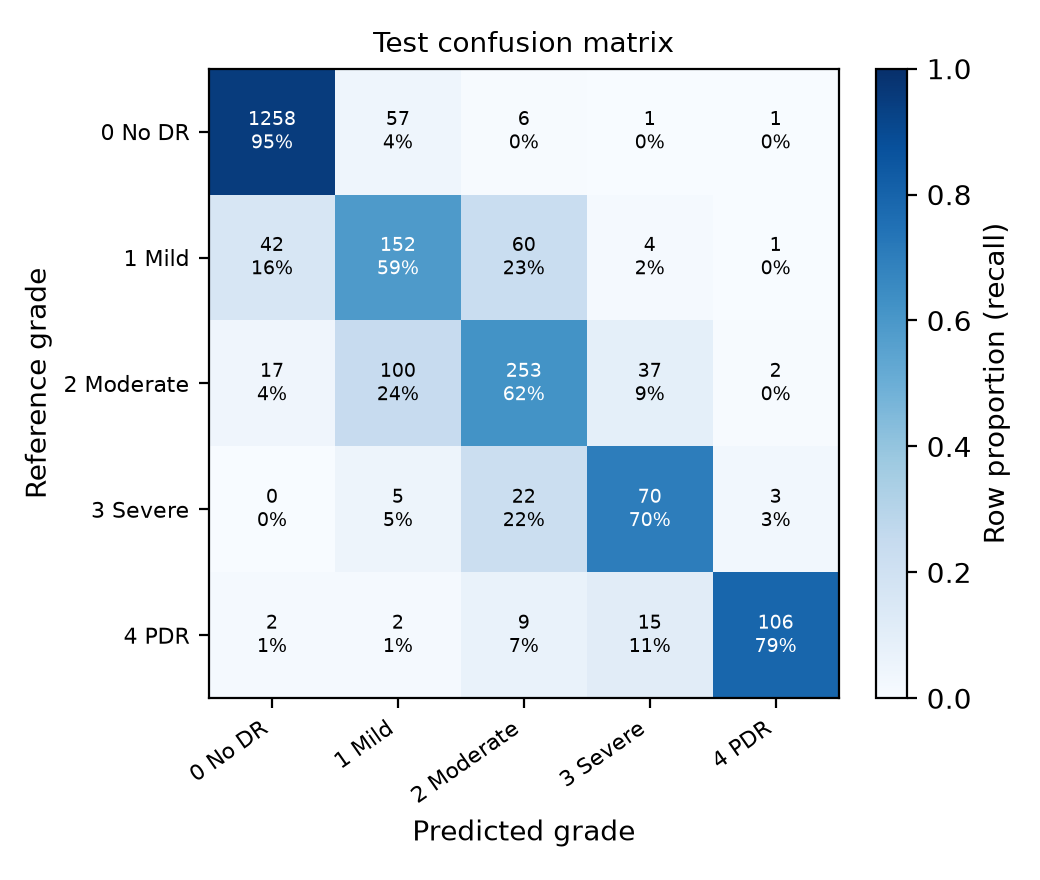

In [5]:
pc = pd.DataFrame(m["performance"]["per_class"]).T
pc.index = [f"{int(g)} {GRADE_NAMES[int(g)]}" for g in pc.index]
display(pc.round(3))
display(Image(str(PRIMARY / "figures" / "confusion_matrix.png"), width=520))

## Error direction
Under-grading is the clinically costly direction for triage: it gives a patient less optometrist time than they need.

In [6]:
e = m["error_direction"]
pd.Series({"errors": e["n_errors"], "share under-graded": e["share_of_errors_under"],
           "share over-graded": e["share_of_errors_over"], "two or more grades out": e["errors_two_or_more_grades"],
           "missed referable (grade >= 2 called < 2)": e["missed_referable"],
           "referable sensitivity": e["referable_sensitivity"], "referable specificity": e["referable_specificity"],
           "referable AUROC": m["referable_auc"]}).round(3).to_frame("value")

,value
errors,386.000
share under-graded,0.554
share over-graded,0.446
two or more grades out,50.000
missed referable (grade >= 2 called < 2),126.000
referable sensitivity,0.804
referable specificity,0.954
referable AUROC,0.972


## Reliability: calibration
Temperature fitted on validation, assessed on test.

temperature 1.503 | ECE uncalibrated 0.056 -> scaled 0.025


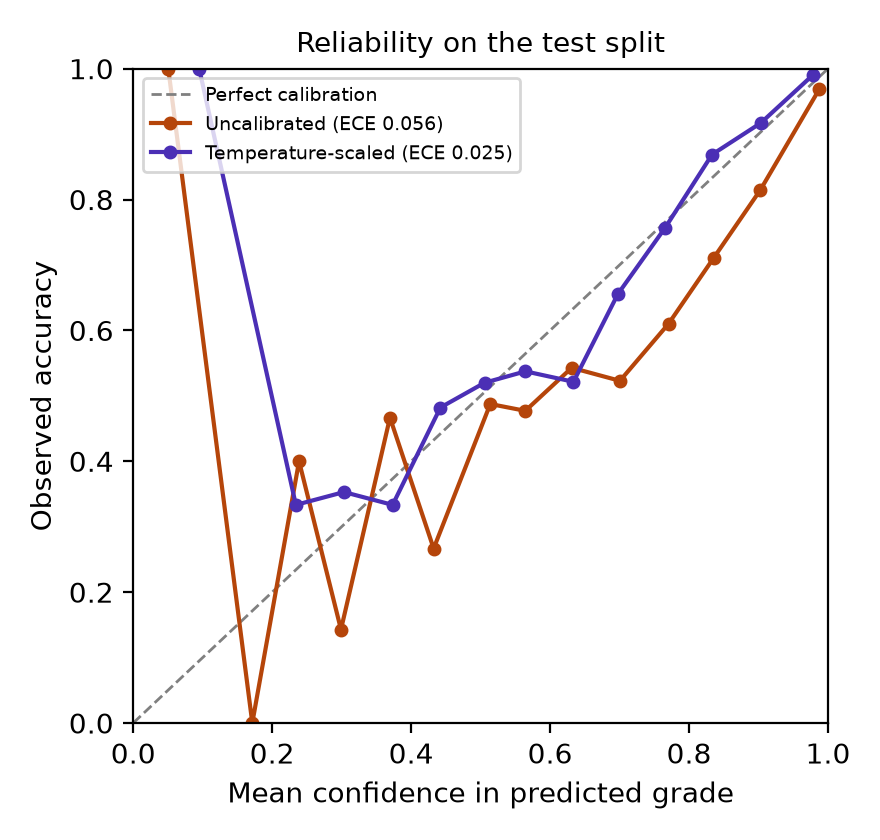

In [7]:
cal = m["calibration"]
print(f"temperature {m['temperature']:.3f} | ECE uncalibrated {cal['ece_uncalibrated']['ece']:.3f} -> scaled {cal['ece_temperature_scaled']['ece']:.3f}")
display(Image(str(PRIMARY / "figures" / "reliability.png"), width=420))

## Reliability: referral rule for triage
Threshold fixed on validation for 80% automatic coverage, then applied to test. Compared with referring the same number of cases at random.

,value
target_coverage,0.800000
threshold,0.636817
achieved_coverage,0.795056
n_referred,456.000000
accuracy_kept,0.907858
qwk_kept,0.950949
accuracy_referred,0.510965
missed_referable_total,126.000000
missed_referable_caught_by_review,70.000000
caught_if_referred_at_random,25.822921


,n_kept,n_referred,accuracy,qwk,missed_referable_kept,missed_referable_caught_by_review,caught_if_referred_at_random
coverage,,,,,,,
1.00,2225,0,0.827,0.908,126,0,0.000
0.95,2114,111,0.848,0.922,112,14,6.286
0.90,2002,223,0.866,0.931,96,30,12.628
0.85,1891,334,0.885,0.939,76,50,18.914
0.80,1780,445,0.906,0.951,57,69,25.200
0.75,1669,556,0.931,0.958,37,89,31.486
0.70,1558,667,0.947,0.965,24,102,37.772
0.60,1335,890,0.972,0.980,12,114,50.400
0.50,1112,1113,0.987,0.992,2,124,63.028


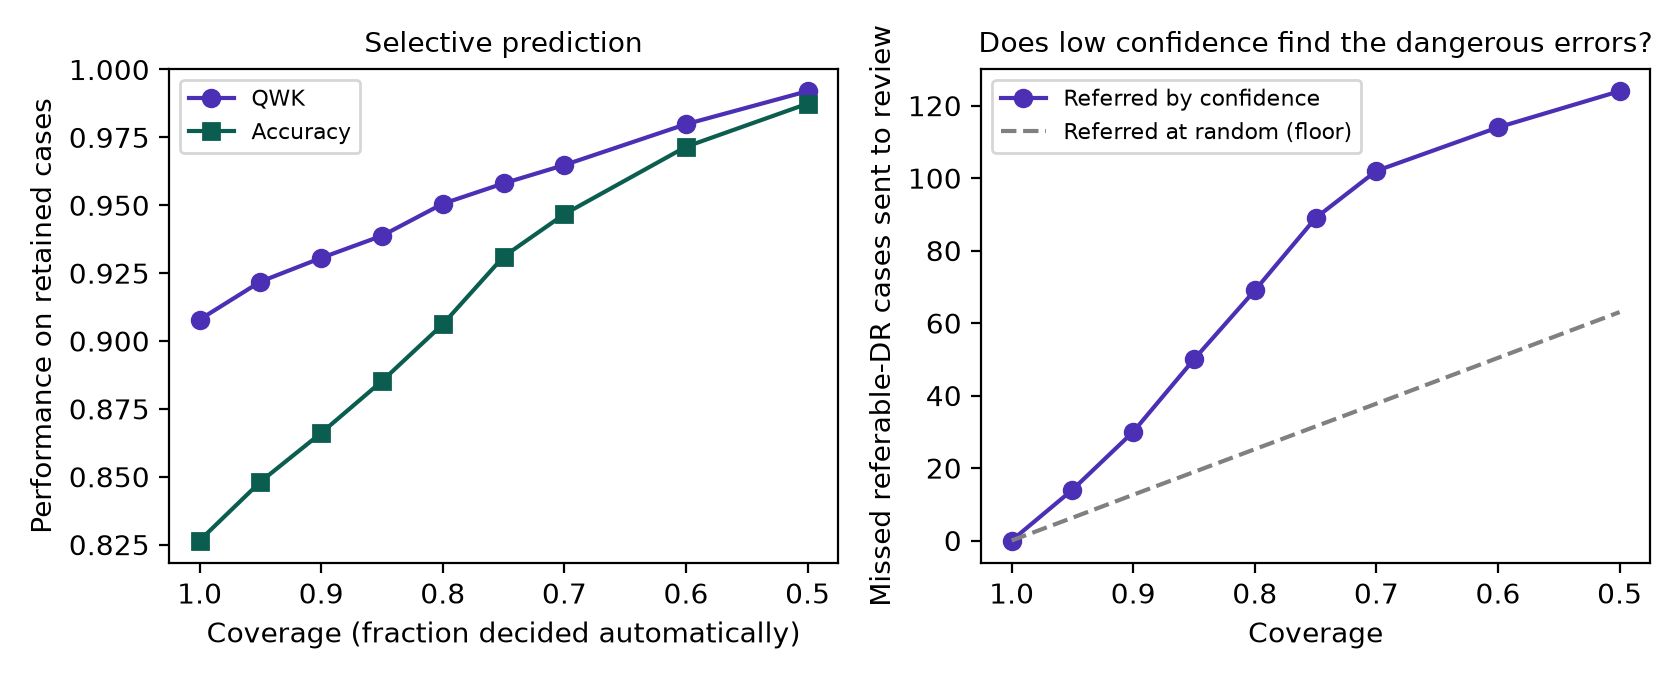

In [8]:
display(pd.Series(m["referral_rule"]).to_frame("value"))
display(pd.DataFrame(m["referral_curve"]).set_index("coverage").round(3))
display(Image(str(PRIMARY / "figures" / "referral_curve.png"), width=760))

## Reliability: image quality
Real sharpness bands (edges from training images), and simulated blur or under-exposure if `--quality` was run. The dangerous pattern is accuracy falling while confidence stays high.

,n,accuracy,qwk,mean_confidence,grade_mix
band,,,,,
low,763,0.796,0.906,0.809,"{'0': 371, '1': 100, '2': 173, '3': 40, '4': 79}"
middle,714,0.819,0.903,0.817,"{'0': 443, '1': 79, '2': 135, '3': 28, '4': 29}"
high,748,0.865,0.906,0.852,"{'0': 509, '1': 80, '2': 101, '3': 32, '4': 26}"


Spearman sharpness vs confidence 0.092; vs correct 0.072


,qwk,accuracy,mean_confidence
condition,,,
blur 0,0.908,0.827,0.826
blur 1,0.905,0.821,0.830
blur 2,0.827,0.757,0.842
blur 4,0.305,0.385,0.677
dark gamma 1.5,0.904,0.825,0.840
dark gamma 2.0,0.872,0.794,0.841


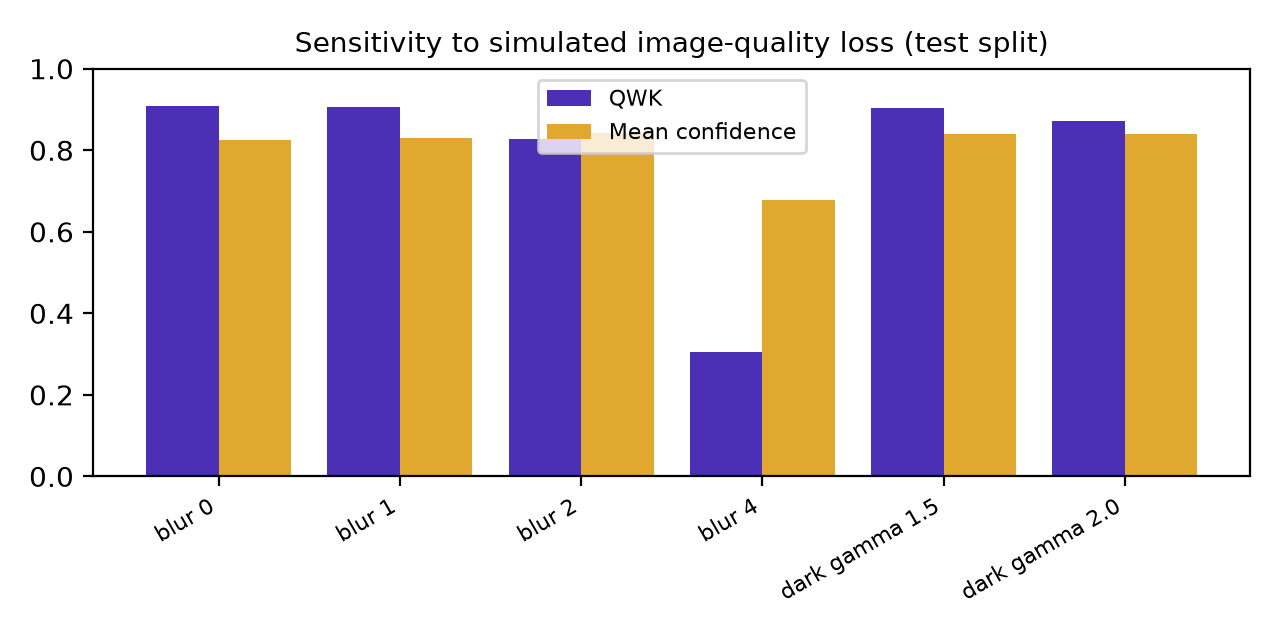

In [9]:
if "quality_strata_sharpness" in m:
    q = m["quality_strata_sharpness"]
    display(pd.DataFrame(q["bands"]).set_index("band").round(3))
    print(f"Spearman sharpness vs confidence {q['spearman_quality_vs_confidence']:.3f}; vs correct {q['spearman_quality_vs_correct']:.3f}")
if "quality_probe" in m:
    display(pd.DataFrame(m["quality_probe"]).set_index("condition").round(3))
    display(Image(str(PRIMARY / "figures" / "quality_probe.png"), width=600))